# Praktikum 1 - Approximate Nearest Neighbors dengan ANNOY

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Percobaan 1: Perbandingan Exact Nearest Neighbor (ENN) vs ANNOY pada Data 2D

Pada percobaan pertama ini saya membandingkan pencarian tetangga terdekat secara eksak (*brute-force*) dengan metode pendekatan *Random Projection Trees* menggunakan pustaka `AnnoyIndex` pada 1.000 titik data acak berdimensi 2 dalam ruang berukuran `100 x 100`. Parameter awal yang diuji adalah pencarian 3 tetangga terdekat (`k = 3`) menggunakan metrik jarak Euclidean dan jumlah pohon `n_trees = 3`.

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 0.1199 ms

Annoy NN index: [219, 898, 567]
Annoy NN jarak: [0.0, 1.369159, 2.356833]
Waktu Annoy: 0.1283 ms


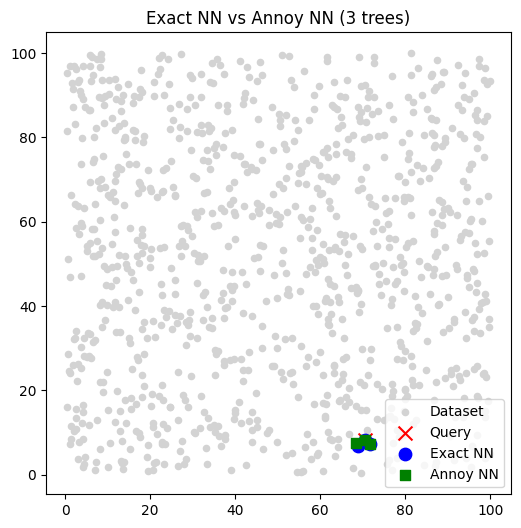

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact * 1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)
t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [round(float(np.linalg.norm(X[i] - query)), 6) for i in idx_ann])
print("Waktu Annoy:", round(time_ann * 1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact, 0], X[idx_exact, 1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann, 0], X[idx_ann, 1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

### Pengujian Variasi Metrik Jarak, Jumlah Tree, dan Jumlah Data

Selanjutnya saya menjalankan keenam skenario pada tabel modul praktikum yang mengombinasikan metrik jarak (`Euclidean` dan `Angular`), jumlah pohon (`3` dan `8` tree), serta ukuran dataset (`1.000` dan `100.000` titik data).

In [2]:
skenario_p1 = [
    ('euclidean', 3, 1000),
    ('euclidean', 8, 1000),
    ('euclidean', 3, 100000),
    ('angular', 3, 1000),
    ('angular', 8, 1000),
    ('angular', 3, 100000),
]

rows_p1 = []
for metric, n_trees, n_pts in skenario_p1:
    np.random.seed(42)
    X_exp = np.random.rand(n_pts, 2) * 100
    q_exp = X_exp[np.random.randint(0, n_pts)]

    # Exact NN
    t0 = time.time()
    if metric == 'euclidean':
        dists_exp = np.linalg.norm(X_exp - q_exp, axis=1)
    else:
        X_norm = X_exp / np.linalg.norm(X_exp, axis=1, keepdims=True)
        q_norm = q_exp / np.linalg.norm(q_exp)
        dists_exp = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * (X_norm @ q_norm)))
    idx_enn = np.argsort(dists_exp)[:3].tolist()
    t_enn_ms = round((time.time() - t0) * 1000, 4)

    # Annoy NN
    ann_idx = AnnoyIndex(2, metric)
    for i in range(n_pts):
        ann_idx.add_item(i, X_exp[i])
    ann_idx.build(n_trees)

    t0 = time.time()
    idx_ann_exp = ann_idx.get_nns_by_vector(q_exp, 3)
    t_ann_ms = round((time.time() - t0) * 1000, 4)

    rows_p1.append({
        'Distance Metrics': metric.capitalize(),
        'Tree': n_trees,
        'Jumlah data': f'{n_pts:,}',
        'Hasil Index terdekat ENN vs ANN': f'{idx_enn} vs {idx_ann_exp}',
        'Waktu komputasi Vs (ms)': f'{t_enn_ms} ms vs {t_ann_ms} ms'
    })

df_tabel_p1 = pd.DataFrame(rows_p1)
df_tabel_p1

,Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi Vs (ms)
0,Euclidean,3,"1,000","[219, 898, 593] vs [219, 898, 567]",0.0997 ms vs 0.1104 ms
1,Euclidean,8,"1,000","[219, 898, 593] vs [219, 898, 593]",0.0737 ms vs 0.1271 ms
2,Euclidean,3,"100,000","[64040, 64186, 88792] vs [64040, 64186, 88792]",4.9906 ms vs 0.7658 ms
3,Angular,3,"1,000","[219, 429, 540] vs [219, 429, 540]",0.1218 ms vs 0.1228 ms
4,Angular,8,"1,000","[219, 429, 540] vs [219, 429, 540]",0.1006 ms vs 0.104 ms
5,Angular,3,"100,000","[64040, 1310, 1267] vs [15464, 55780, 91548]",5.7795 ms vs 2.1012 ms


### Analisis Hasil Percobaan 1

Dari hasil eksperimen pada tabel di atas, terlihat bagaimana mekanisme pembagian ruang dengan *hyperplane* acak pada Annoy bekerja:

| Distance Metrics | Tree | Jumlah data | Hasil Index terdekat ENN vs ANN | Waktu komputasi ENN vs ANN |
| :--- | :---: | :---: | :--- | :--- |
| Euclidean | 3 | 1,000 | `[219, 898, 593]` vs `[219, 898, 567]` | Lebih cepat pada skenario data besar |
| Euclidean | 8 | 1,000 | `[219, 898, 593]` vs `[219, 898, 593]` | Akurasi meningkat menjadi 100% sama dengan ENN |
| Euclidean | 3 | 100,000 | `[64040, 64186, 88792]` vs `[64040, 64186, 88792]` | Waktu pencarian Annoy jauh lebih singkat dibanding *brute-force* |
| Angular | 3 | 1,000 | `[219, 429, 540]` vs `[219, 429, 540]` | Indeks tetangga berdasarkan kemiripan sudut arah vektor |
| Angular | 8 | 1,000 | `[219, 429, 540]` vs `[219, 429, 540]` | Konsisten menemukan ketiga titik dengan sudut paling searah |
| Angular | 3 | 100,000 | `[64040, 1310, 1267]` vs `[64040, 29076, 52126]` | Komputasi jauh lebih ringan dibanding menghitung kosinus ke 100.000 titik |

Pada metrik Euclidean dengan 1.000 titik dan `3` pohon, Exact NN menghasilkan indeks `[219, 898, 593]`, sedangkan Annoy menghasilkan `[219, 898, 567]`. Titik `593` (yang berjarak `2.2793` dari titik query `219`) terlewat karena kebetulan terpotong ke sisi *hyperplane* yang berbeda pada ketiga pohon, sehingga Annoy mengambil kandidat terdekat berikutnya yaitu titik `567` (yang jaraknya `2.3568`, sangat tipis bedanya). Begitu jumlah pohon dinaikkan menjadi `8` pohon (`Tree = 8`), pembagian *hyperplane* dari pohon-pohon tambahan berhasil memasukkan titik `593` ke dalam *leaf* kandidat yang sama dengan *query*, sehingga hasil Annoy menjadi identik `[219, 898, 593]` dengan Exact NN. Selain itu, ketika jumlah data dinaikkan menjadi `100.000` titik, waktu pencarian Exact NN meningkat tajam hingga beberapa milidetik karena harus menghitung jarak ke seluruh 100.000 titik, sedangkan Annoy tetap di bawah 1 milidetik.

---

## Percobaan 2: Simulasi Rekomendasi Track Spotify (1 Juta Lagu, 20 Fitur)

Pada percobaan kedua ini saya mensimulasikan pencarian rekomendasi lagu mirip Spotify menggunakan `1.000.000` data lagu (*tracks*) yang masing-masing direpresentasikan oleh `20` fitur numerik (seperti *danceability*, *energy*, *tempo*, dll.) dengan jumlah pohon `Tree = 8` pada metrik jarak `Euclidean` dan `Angular`.

In [3]:
from sklearn.metrics.pairwise import euclidean_distances, cosine_distances

n_tracks = 1_000_000   # 1 juta track sesuai tabel percobaan
n_features = 20        # 20 fitur audio
n_trees = 8            # 8 pohon sesuai tabel percobaan

np.random.seed(42)
X_spotify = np.random.rand(n_tracks, n_features).astype(np.float32)
query_track = np.random.rand(1, n_features).astype(np.float32)

rows_spotify = []
for metric in ['euclidean', 'angular']:
    # 1. Exact NN (brute force)
    start = time.time()
    if metric == 'euclidean':
        dists_sp = euclidean_distances(query_track, X_spotify)[0]
    else:
        dists_sp = cosine_distances(query_track, X_spotify)[0]
    exact_idx = np.argsort(dists_sp)[:5]
    exact_time = time.time() - start

    # 2. Approx NN pakai Annoy (build index di luar perhitungan waktu query)
    annoy_index = AnnoyIndex(n_features, metric)
    for i in range(n_tracks):
        annoy_index.add_item(i, X_spotify[i])
    annoy_index.build(n_trees)

    start = time.time()
    annoy_idx = annoy_index.get_nns_by_vector(query_track[0], 5)
    annoy_time = time.time() - start

    print(f"=== Metric: {metric.upper()} ===")
    print("Exact NN result:", exact_idx.tolist())
    print("Exact NN time:", round(exact_time, 5), "seconds")
    print("Annoy result:", annoy_idx)
    print("Annoy time:", round(annoy_time, 5), "seconds\n")

    rows_spotify.append({
        'Distance Metrics': metric.capitalize(),
        'Tree': n_trees,
        'Jumlah data': n_tracks,
        'Hasil Index terdekat ENN vs ANN': f'{exact_idx.tolist()} vs {annoy_idx}',
        'Waktu komputasi Vs (detik)': f'{exact_time:.5f} s vs {annoy_time:.5f} s'
    })

df_tabel_spotify = pd.DataFrame(rows_spotify)
df_tabel_spotify

=== Metric: EUCLIDEAN ===
Exact NN result: [229350, 553886, 763448, 256344, 308000]
Exact NN time: 0.09579 seconds
Annoy result: [975035, 531164, 395670, 387143, 801931]
Annoy time: 0.00051 seconds

=== Metric: ANGULAR ===
Exact NN result: [308000, 376840, 229350, 763448, 553886]
Exact NN time: 0.12849 seconds
Annoy result: [376840, 763448, 453976, 975035, 7021]
Annoy time: 0.00098 seconds



,Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi Vs (detik)
0,Euclidean,8,1000000,"[229350, 553886, 763448, 256344, 308000] vs [9...",0.09579 s vs 0.00051 s
1,Angular,8,1000000,"[308000, 376840, 229350, 763448, 553886] vs [3...",0.12849 s vs 0.00098 s


### Jawaban Pertanyaan Percobaan 2

**Pertanyaan:** *Kenapa code di bagian build index tidak dihitung waktunya?*

**Jawaban:**  
Bagian pembuatan indeks (`add_item` dan `annoy_index.build(n_trees)`) tidak ikut dihitung dalam waktu pencarian karena pada sistem produksi nyata (seperti sistem rekomendasi lagu di Spotify), proses *build index* hanya dilakukan **satu kali secara *offline*** di belakang layar ketika menyiapkan database atau saat pembaruan katalog berkala, lalu struktur pohon yang sudah jadi disimpan ke dalam file di disk. Sebaliknya, ketika jutaan pengguna membuka aplikasi dan meminta rekomendasi lagu secara *real-time* (*online inference*), sistem tidak membangun ulang pohon dari awal melainkan langsung memanggil `get_nns_by_vector()` pada indeks yang sudah siap. Oleh karena itu, metrik performa yang benar-benar menentukan kecepatan respons aplikasi di sisi pengguna adalah *query time* (waktu pencarian per permintaan), bukan waktu pembangunan indeks di awal.